# Bus Stops Analysis
Public transportation is an important part of daily life, especially for people who do not own a car or prefer not to drive. Having more bus stops in a neighborhood can make it easier for residents to travel to work, school, grocery stores, and other places. We will be using the Transportation Stops dataset from the Western Pennsylvania Regional Data Center [(WPRDC)](https://data.wprdc.org/dataset/prt-of-allegheny-county-transit-stops/resource/d6e6ed6e-9220-4a0e-9796-e72d83ce8e7a?view_id=95dbcff8-a0f9-4ea1-ba39-1327ed75b202) to rank areas in Pittsburgh based on the number of bus stops available. Although the dataset includes buses, light rail (T), and inclines, our main focus will be on bus stops since buses are the most common transportation option in the dataset. Our goal is to determine which area has the most bus stops and use this as a way to measure public transportation accessibility.

## Data Omitted

The Transportation Stops dataset contains information about different types of public transportation stopsb but not all columns are needed for our analysis. The following table shows which data points were excluded and why.

| Data Point | Reason |
| :--- | :--- |
| `_id` | Not needed for counting bus stops |
| `route_code` | Not needed for our ranking |
| RAIL | Our analysis focuses on bus stops |
| INCLINE | Our analysis focuses on bus stops |
| Missing area information | Cannot identify which area the stop belongs to |

We will mainly use `mode` to identify bus stops, `munihood_full` to identify the area, and `stop_name` to check for possible duplicate stops. The original dataset will remain unchanged. We will only filter unnecessary data using Pandas.

## Counting Bus Stops

To determine which area has the most bus stops, we will first filter the dataset to include only bus stops. We will also check for possible duplicate stops using their names. However, stops with the same name are not necessarily duplicates, since different stops may share similar names.

After checking the data, we will group the bus stops by area and count the number of records in each one. The results will then be sorted from highest to lowest to determine which areas have the most bus stops.

In [2]:
import pandas as pd

# Read CSV file
df = pd.read_csv("TransportationStops.csv")

# Keep relevant columns
df = df[["mode", "munihood_full", "stop_name"]]

# Keep only bus stops
bus = df[df["mode"] == "BUS"].copy()

# Remove records without an area
bus = bus.dropna(subset=["munihood_full"])

display(bus.head())

,mode,munihood_full,stop_name
4,BUS,"Strip District, Pittsburgh",26TH ST AT PENN AVE FS (SPRING WAY)
5,BUS,"Polish Hill, Pittsburgh",28TH ST AT LIBERTY AVE
6,BUS,"Strip District, Pittsburgh",32ND ST AT SPRING WAY
7,BUS,"Lower Lawrenceville, Pittsburgh",40TH ST AT BUTLER ST
8,BUS,"Central Lawrenceville, Pittsburgh",40TH ST AT DAVIDSON ST FS


In [3]:
# Check for possible duplicate stops
duplicates = bus[
    bus.duplicated(
        subset=["munihood_full", "stop_name"],
        keep=False
    )
]

display(
    duplicates.sort_values(
        by=["munihood_full", "stop_name"]
    )
)

print("Possible duplicate records:", len(duplicates))

,mode,munihood_full,stop_name
4125,BUS,"Allegheny West, Pittsburgh",WESTERN AVE AT GALVESTON AVE
4129,BUS,"Allegheny West, Pittsburgh",WESTERN AVE AT GALVESTON AVE
3695,BUS,"Allentown, Pittsburgh",ARLINGTON AVE AT FREELAND ST
4445,BUS,"Allentown, Pittsburgh",ARLINGTON AVE AT FREELAND ST
4452,BUS,"Allentown, Pittsburgh",ARLINGTON AVE AT WARRINGTON AVE
...,...,...,...
1542,BUS,"Wilkinsburg bgh, Allegheny County",WOOD ST AT HILL AVE
1547,BUS,"Wilkinsburg bgh, Allegheny County",WOOD ST AT WALLACE AVE
1548,BUS,"Wilkinsburg bgh, Allegheny County",WOOD ST AT WALLACE AVE
5593,BUS,"Windgap, Pittsburgh",WINDGAP AVE AT BELHURST AVE


Possible duplicate records: 878


In [4]:
# Count bus stop records by area
bus_counts = (
    bus.groupby("munihood_full")
    .size()
    .sort_values(ascending=False)
)

# Display top 20 areas
display(bus_counts.head(20))

munihood_full
Penn Hills twp, Allegheny County        264
West Mifflin bgh, Allegheny County      172
Wilkinsburg bgh, Allegheny County       160
Ross twp, Allegheny County              156
Monroeville muni, Allegheny County      124
McKeesport city, Allegheny County       114
McCandless twp, Allegheny County        106
Scott twp, Allegheny County              99
Mount Lebanon twp, Allegheny County      96
Bloomfield, Pittsburgh                   93
Whitehall bgh, Allegheny County          92
Mount Washington, Pittsburgh             91
Baldwin bgh, Allegheny County            90
Duquesne city, Allegheny County          83
Lincoln-Lemington-Belmar, Pittsburgh     80
Shadyside, Pittsburgh                    76
Squirrel Hill North, Pittsburgh          76
Greenfield, Pittsburgh                   71
Squirrel Hill South, Pittsburgh          70
Brookline, Pittsburgh                    69
dtype: int64

## Ranking the Top 10

After counting the bus stops in each area, we can compare the results to see which areas have the most bus stops. The following graph shows the top 10 areas with the highest number of bus stops. We assume that areas with more bus stops may provide better public transportation accessibility because residents have more possible locations to board a bus. However, this ranking only considers the number of bus stops and does not account for bus frequency, waiting times, or the size of each area.

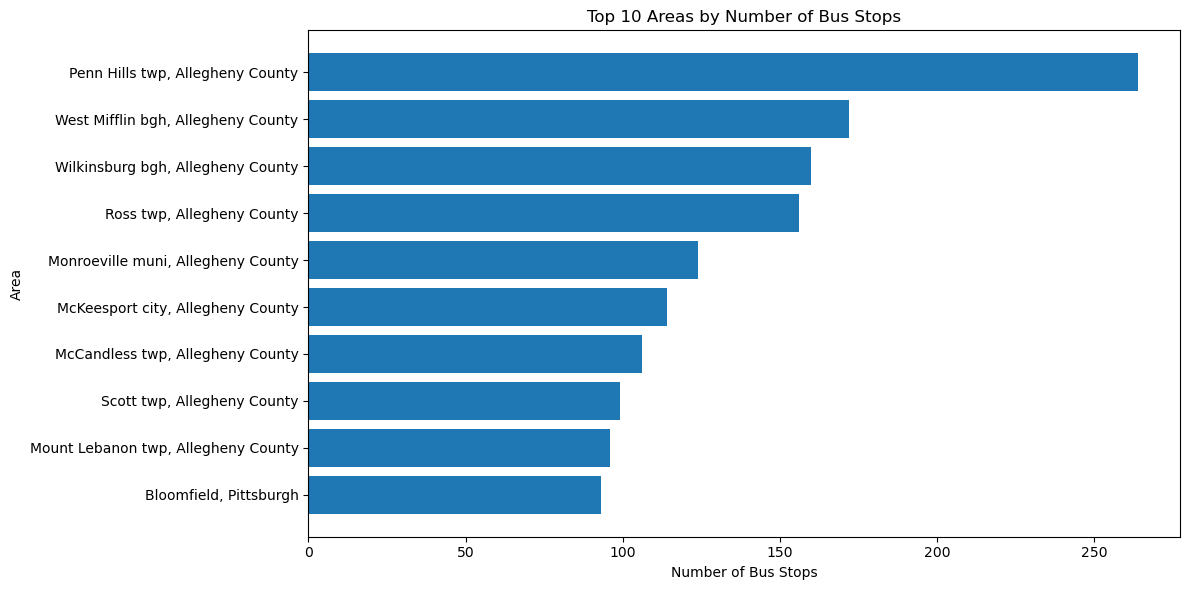

In [5]:
import matplotlib.pyplot as plt

# Select top 10 areas
top10 = bus_counts.head(10)

# Create horizontal bar chart
plt.figure(figsize=(12, 6))

plt.barh(top10.index, top10.values)

plt.xlabel("Number of Bus Stops")
plt.ylabel("Area")
plt.title("Top 10 Areas by Number of Bus Stops")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## The Best Area

In [6]:
best_area = bus_counts.index[0]
best_count = bus_counts.iloc[0]

print("Area with the most bus stops:", best_area)
print("Number of bus stops:", best_count)

Area with the most bus stops: Penn Hills twp, Allegheny County
Number of bus stops: 264


Based on the number of bus stops, Penn Hills Township ranks first with 264 bus stops. This area has the highest number of bus stops in our dataset, suggesting that residents may have more locations to access bus transportation. But this does not necessarily mean that the bus service is faster or more reliable than in other areas. Our metric focuses on the availability of bus stops rather than the actual quality of bus service.